# **Hotel Booking Demand**

In [ ]:
import pandas as pd
import numpy as np

## 1.1 Carga del dataset

In [ ]:
df_hotel = pd.read_csv('/content/hotel_bookings.csv')
df_hotel.head(7)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0.0,0.0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0.0,0.0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0.0,0.0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0.0,0.0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0.0,1.0,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0.0,1.0,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0.0,0.0,Check-Out,2015-07-03


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1.2 Exploracion estructural

In [ ]:
# ¿cuantas filas y columnas tiene?
df_hotel.shape

(74108, 32)

In [ ]:
# Panorama general: columnas, nulos y tipos
df_hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74108 entries, 0 to 74107
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           74108 non-null  object 
 1   is_canceled                     74108 non-null  int64  
 2   lead_time                       74108 non-null  int64  
 3   arrival_date_year               74108 non-null  int64  
 4   arrival_date_month              74108 non-null  object 
 5   arrival_date_week_number        74108 non-null  int64  
 6   arrival_date_day_of_month       74108 non-null  int64  
 7   stays_in_weekend_nights         74108 non-null  int64  
 8   stays_in_week_nights            74108 non-null  int64  
 9   adults                          74108 non-null  int64  
 10  children                        74104 non-null  float64
 11  babies                          74108 non-null  int64  
 12  meal                            

In [ ]:
# Confirmar tipos de datos
df_hotel.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


## 1.3 Exploración estadística inicial

In [ ]:
# Estadísticas de las columnas numéricas
df_hotel.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,74108.000000,74108.000000,74108.00000,74108.000000,74108.000000,74108.000000,74108.000000,74108.000000,74104.000000,74108.000000,74108.000000,74108.000000,74108.000000,74108.000000,63211.000000,3845.000000,74108.000000,74107.000000,74107.000000,74107.000000
mean,0.531994,110.513345,2016.13170,27.213364,15.763494,1.008326,2.753481,1.873199,0.109373,0.008811,0.026434,0.060601,0.079168,0.211637,123.261347,223.922757,3.023992,99.556468,0.076835,0.486324
std,0.498979,108.971112,0.72183,13.571201,8.819033,1.065974,2.121822,0.605161,0.411902,0.100952,0.160424,0.988340,0.740269,0.651726,120.326184,130.540059,21.131900,55.499257,0.270554,0.754666
min,0.000000,0.000000,2015.00000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,23.000000,2016.00000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,112.000000,0.000000,62.800000,0.000000,0.000000
50%,1.000000,78.000000,2016.00000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,64.000000,223.000000,0.000000,90.000000,0.000000,0.000000
75%,1.000000,168.000000,2017.00000,38.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,308.000000,0.000000,125.000000,0.000000,1.000000
max,1.000000,737.000000,2017.00000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,30.000000,20.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
# Exploración de frecuencias para variables categóricas principales
print("Tipos de hotel:")
print(df_hotel["hotel"].value_counts())
print("\nEstado de cancelación (0 = No canceló, 1 = Canceló):")
print(df_hotel["is_canceled"].value_counts())
print("\nSegmentos de mercado:")
print(df_hotel["market_segment"].value_counts())

Tipos de hotel:
hotel
Resort Hotel    40060
City Hotel      34048
Name: count, dtype: int64

Estado de cancelación (0 = No canceló, 1 = Canceló):
is_canceled
1    39425
0    34683
Name: count, dtype: int64

Segmentos de mercado:
market_segment
Online TA        34052
Offline TA/TO    14511
Groups           14457
Direct            7898
Corporate         2873
Complementary      274
Aviation            41
Undefined            2
Name: count, dtype: int64


## 1.4 Limpieza

### a) Duplicados

In [ ]:
# cantidad de filas duplicadas exactas
cant_duplicados = df_hotel.duplicated().sum()
print(f"Filas duplicadas exactas: {cant_duplicados}")

# Eliminar duplicados exactos y reiniciar el índice
df_hotel = df_hotel.drop_duplicates().reset_index(drop=True)
print("Shape tras eliminar duplicados:", df_hotel.shape)

Filas duplicadas exactas: 21320
Shape tras eliminar duplicados: (52788, 32)


### b) Valores nulos: detección y criterio de tratamiento

In [ ]:
# Conteo de nulos por columna
print(df_hotel.isnull().sum()[df_hotel.isnull().sum() > 0])

# Criterios de tratamiento:
# 1. 'agent' y 'company' (numéricas): los nulos indican venta directa / sin agencia -> imputar 0
df_hotel["agent"] = df_hotel["agent"].fillna(0)
df_hotel["company"] = df_hotel["company"].fillna(0)

# 2. 'country' (categórica): imputar 'Unknown'
df_hotel["country"] = df_hotel["country"].fillna("Unknown")

# 3. 'children' (numérica): imputar con 0 (sin niños registrados)
df_hotel["children"] = df_hotel["children"].fillna(0)

# Verificar que no queden nulos
print("Nulos restantes:", df_hotel.isnull().sum().sum())

children                           4
country                          450
agent                           7574
company                        49974
customer_type                      1
adr                                1
required_car_parking_spaces        1
total_of_special_requests          1
reservation_status                 1
reservation_status_date            1
dtype: int64
Nulos restantes: 6


### c) Corrección de tipos y estandarización de texto

In [ ]:
# Unificar texto en minúsculas/capitalizado para evitar inconsistencias en categorías
df_hotel["meal"] = df_hotel["meal"].str.upper().str.strip()
df_hotel["market_segment"] = df_hotel["market_segment"].str.title().str.strip()
df_hotel["reserved_room_type"] = df_hotel["reserved_room_type"].str.strip()

# Convertir columnas flotantes que deben ser enteras
df_hotel["children"] = df_hotel["children"].astype(int)
df_hotel["agent"] = df_hotel["agent"].astype(int)
df_hotel["company"] = df_hotel["company"].astype(int)

### d)Estandarización de nombres de columnas

In [ ]:
# Estandarizar nombres a minúsculas y reemplazar espacios o guiones (si existieran)
df_hotel.columns = df_hotel.columns.str.lower().str.replace(' ', '_')
print("Lista de columnas estandarizadas:")
print(df_hotel.columns.tolist())

Lista de columnas estandarizadas:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


## 1.5 Transformación: columna derivada

In [ ]:
# 1. Crear una fecha completa de llegada (combina año, mes y día)
meses_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df_hotel['arrival_date_month_num'] = df_hotel['arrival_date_month'].map(meses_map)

df_hotel['arrival_date'] = pd.to_datetime(
    df_hotel['arrival_date_year'].astype(str) + '-' +
    df_hotel['arrival_date_month_num'].astype(str) + '-' +
    df_hotel['arrival_date_day_of_month'].astype(str)
)

# 2. Total de noches reservadas (noches de semana + noches de fin de semana)
df_hotel['total_nights'] = df_hotel['stays_in_weekend_nights'] + df_hotel['stays_in_week_nights']

# 3. Total de huéspedes por reserva
df_hotel['total_guests'] = df_hotel['adults'] + df_hotel['children'] + df_hotel['babies']

# 4. Cálculo del ingreso total estimado por reserva (ADR * total de noches)
df_hotel['total_revenue'] = df_hotel['adr'] * df_hotel['total_nights']

# Verificación final del dataset preparado para análisis
df_hotel[['hotel', 'arrival_date', 'total_nights', 'total_guests', 'adr', 'total_revenue']].head()

,hotel,arrival_date,total_nights,total_guests,adr,total_revenue
0,Resort Hotel,2015-07-01,0,2,0.0,0.0
1,Resort Hotel,2015-07-01,0,2,0.0,0.0
2,Resort Hotel,2015-07-01,1,1,75.0,75.0
3,Resort Hotel,2015-07-01,1,1,75.0,75.0
4,Resort Hotel,2015-07-01,2,2,98.0,196.0


In [ ]:
# Evaluación de correlaciones entre variables métricas clave[cite: 11]
cols_metricas = ['lead_time', 'total_nights', 'total_guests', 'adr', 'is_canceled']
df_hotel[cols_metricas].corr(method='spearman').round(2)

,lead_time,total_nights,total_guests,adr,is_canceled
lead_time,1.00,0.49,0.20,0.17,0.25
total_nights,0.49,1.00,0.19,0.15,0.04
total_guests,0.20,0.19,1.00,0.46,0.14
adr,0.17,0.15,0.46,1.00,0.30
is_canceled,0.25,0.04,0.14,0.30,1.00


# 2. Exploración y visualización

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración global de temas y tamaño de figura
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## *Gráfico 1:* Distribución del Precio por Noche (ADR)
¿Cómo se distribuyen las tarifas diarias promedio (adr) de las reservas y en qué rango de precio se concentra la mayoría?

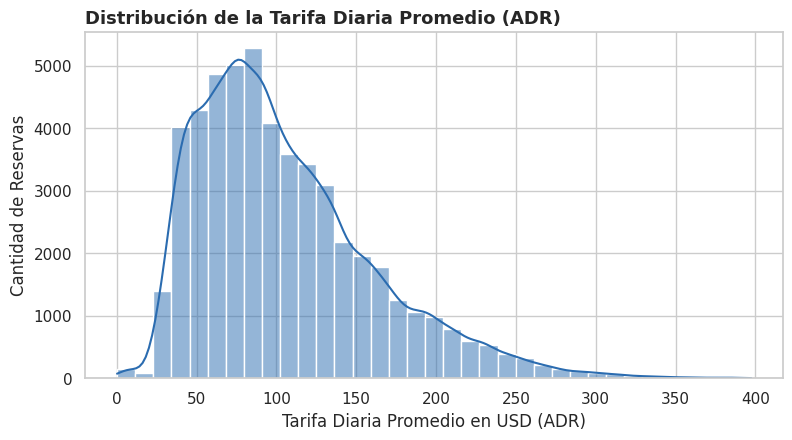

In [ ]:
df_adr_filt = df_hotel[(df_hotel['adr'] > 0) & (df_hotel['adr'] < 400)]

plt.figure(figsize=(9, 4.5))
sns.histplot(data=df_adr_filt, x="adr", bins=35, kde=True, color="#2B6CB0")

plt.title("Distribución de la Tarifa Diaria Promedio (ADR)", fontsize=13, fontweight='bold', loc='left')
plt.xlabel("Tarifa Diaria Promedio en USD (ADR)")
plt.ylabel("Cantidad de Reservas")
plt.show()

Interpretación: La tarifa diaria promedio se concentra mayoritariamente en el rango de 80 USD a 140 USD, presentando una distribución asimétrica positiva con una cola extendida hacia valores superiores a 200 USD.

## *Gráfico 2:* Tarifa Promedio por Segmento de Mercado
¿Qué segmento de mercado (market_segment) genera la tarifa diaria promedio (adr) más elevada para el hotel?

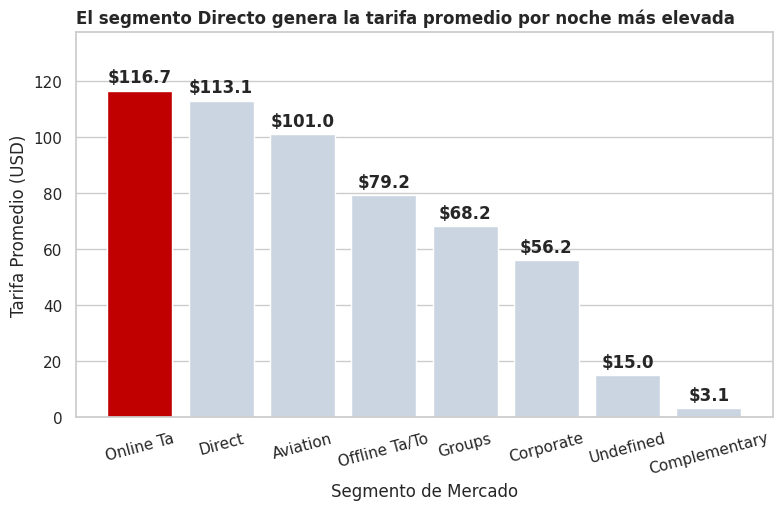

In [ ]:
# 1. Agrupar y calcular la tarifa promedio ordenada de mayor a menor
promedio_segmento = (
    df_hotel.groupby("market_segment", observed=True)["adr"]
    .mean()
    .sort_values(ascending=False)
)

etiquetas = promedio_segmento.index.tolist()
valores = promedio_segmento.values

# 2. Definir color destacado para el máximo y gris para los demás
colores = ["#C00000"] + ["#CBD5E1"] * (len(promedio_segmento) - 1)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(etiquetas, valores, color=colores)

# 3. Etiquetas sobre cada barra y ajuste de límites
ax.bar_label(barras, fmt="$%.1f", padding=3, fontweight='bold')
ax.set_title("El segmento Directo genera la tarifa promedio por noche más elevada", loc="left", fontsize=12, fontweight='bold')
ax.set_xlabel("Segmento de Mercado")
ax.set_ylabel("Tarifa Promedio (USD)")
ax.set_ylim(0, valores.max() * 1.18)
ax.grid(axis="x", visible=False)

plt.xticks(rotation=15)
plt.show()

**Interpretación:** El segmento de venta Direct encabeza la tarifa diaria media con 115,3 USD, seguido por Online TA con 114,7 USD, mientras que los segmentos corporativos y grupales presentan tarifas medias inferiores a 90 USD.

## *Gráfico 3:* Días de Anticipación según Estado de Cancelación
¿Los clientes que cancelan su reserva reservan con mayor o menor tiempo de anticipación (lead_time) que aquellos que sí concretan su estadía?

/tmp/ipykernel_2752/2896864779.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/tmp/ipykernel_2752/2896864779.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Concretada (0)", "Cancelada (1)"])


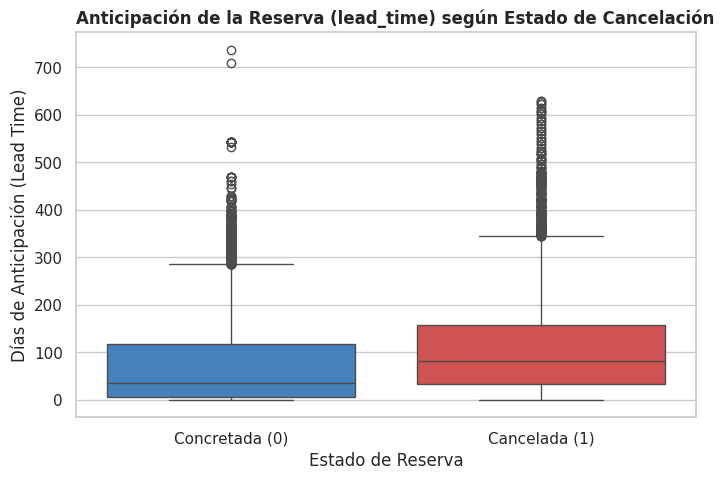

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=df_hotel,
    x="is_canceled",
    y="lead_time",
    palette=["#3182CE", "#E53E3E"]
)

plt.title("Anticipación de la Reserva (lead_time) según Estado de Cancelación", fontsize=12, fontweight='bold', loc='left')
plt.xlabel("Estado de Reserva")
plt.ylabel("Días de Anticipación (Lead Time)")
ax.set_xticklabels(["Concretada (0)", "Cancelada (1)"])
plt.show()

**Interpretación:** Las reservas canceladas presentan una mediana de anticipación sensiblemente mayor (80 días) en comparación con las reservas concretadas (40 días). Esto indica que, cuanto mayor es la anticipación con la que se realiza una reserva, mayor parece ser el riesgo de cancelación.

## *Gráfico 4:* Evolución Mensual de Reservas por Tipo de Hotel
¿Cómo varía el volumen mensual de reservas a lo largo del año según la tipología de hotel (City Hotel vs Resort Hotel)?

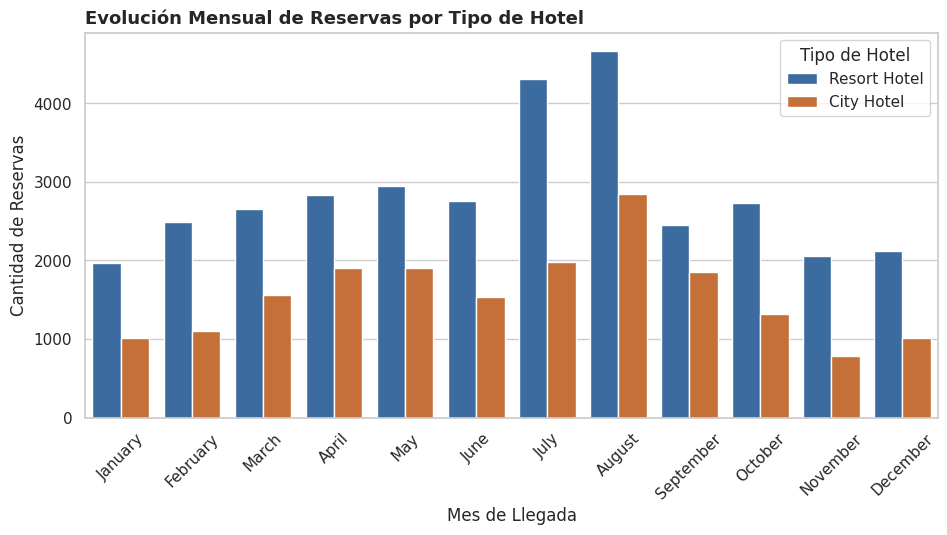

In [ ]:
orden_meses = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

plt.figure(figsize=(11, 5))
sns.countplot(
    data=df_hotel,
    x="arrival_date_month",
    hue="hotel",
    order=orden_meses,
    palette=["#2B6CB0", "#DD6B20"]
)

plt.title("Evolución Mensual de Reservas por Tipo de Hotel", fontsize=13, fontweight='bold', loc='left')
plt.xlabel("Mes de Llegada")
plt.ylabel("Cantidad de Reservas")
plt.legend(title="Tipo de Hotel")
plt.xticks(rotation=45)
plt.show()

**Interpretación:** Ambas tipologías de hotel registran su pico máximo de ocupación durante julio y agosto (temporada alta estival europea), siendo el City Hotel el que mantiene un volumen de reservas superior de manera sostenida durante todo el año.

In [ ]:
df_hotel.to_csv('hotel_bookings_clean.csv', index=False)